## Phase 1: Environment Setup and Data Ingestion [Data Ingestion]
Load required analytical libraries and read the raw sales transactions dataset.

In [75]:
# Cell 1: Import required analytical libraries and load the raw sales dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Portable dataset resolution (Colab, local, and subfolder compatible)
dataset_filename = "New_Query_2026_10_22_10_01_37.csv"
dataset_path = dataset_filename
if not os.path.exists(dataset_path):
    for candidate in [os.path.join("..", dataset_filename), os.path.join("data", dataset_filename)]:
        if os.path.exists(candidate):
            dataset_path = candidate
            break

df = pd.read_csv(dataset_path)

print("Dataset Loaded Successfully!")

# Finding: Successfully loaded core analytical libraries and ingested the raw sales dataset.


Dataset Loaded Successfully!


## Phase 2: Dimension Inspection [Data Understanding]
Verify the total count of rows and columns in the imported dataset.

In [2]:
# Cell 2: Check dataset dimensions (total rows and columns)

print(f"Dataset Dimensions (Rows, Columns): {df.shape}")

# Finding: Dataset contains 2,172 transaction rows and 33 feature columns.


Number of Rows: 2172
Number of Columns: 33


## Phase 3: Column Header Overview [Data Understanding]
Retrieve and review the complete list of attribute names.

In [3]:
# Cell 3: Display all column names in the dataset

print("Column Names:")
print(df.columns.tolist())

# Finding: Identified 33 attribute columns including transactional, product, customer, and temporal fields.


Column Names:
['Order', 'ProductID', 'Quantity', 'Sales', 'Discount', 'COS', 'GP', 'EmployeeID', 'CustomerID', 'OrderDate', 'ShipperID', 'Freight', 'EmployeeName', 'Extension', 'HireDate', 'Office', 'ReportsTo', 'Title', 'YearSalary', 'Customer', 'ContactName', 'Fax', 'Phone', 'PostalCode', 'CountryCode', 'Latitude', 'Longitude', 'City', 'Country', 'ProductName', 'SupplierID', 'CategoryName', 'CategoryDescription']


## Phase 4: Initial Data Exploration and Summary Statistics [Exploratory Data Analysis]
Inspect sample records, structural schema info, and numerical distribution statistics.

In [4]:
# Cell 4: Initial data exploration (sample records, schema info, and descriptive statistics)

print("--- First 5 Records ---")
display(df.head())

print("\n--- Dataset Information ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe())

# Finding: Inspected first 5 rows, confirmed 33 column types/memory info, and reviewed statistical summaries.


,Order,ProductID,Quantity,Sales,Discount,COS,GP,EmployeeID,CustomerID,OrderDate,...,PostalCode,CountryCode,Latitude,Longitude,City,Country,ProductName,SupplierID,CategoryName,CategoryDescription
0,11016,36,16,138.56,0.0,122.2099,16.3501,1,42,2014-01-07T00:00:00.000Z,...,NaN,CA,49.265988,-123.126486,Vancouver,Canada,Mehmet-Tröja,17,Babywear,0-3 Years
1,11017,3,25,538.25,0.0,486.1304,52.1196,7,44,2014-09-10T00:00:00.000Z,...,60528.0,DE,50.073420,8.636150,Frankfurt a.M.,Germany,Chantell Shirt,1,Womens wear,Fashion for Women
2,11017,59,110,933.90,0.0,823.6998,110.2002,7,44,2014-09-10T00:00:00.000Z,...,60528.0,DE,50.073420,8.636150,Frankfurt a.M.,Germany,Rasta WCT,28,Sportwear,Sports…
3,11017,70,30,952.80,0.0,848.3997,104.4003,7,44,2014-09-10T00:00:00.000Z,...,60528.0,DE,50.073420,8.636150,Frankfurt a.M.,Germany,US-Master Jeans,7,Men´s Clothes,Fashion for Men
4,11018,12,20,194.20,0.0,171.2844,22.9156,1,48,2014-04-10T00:00:00.000Z,...,97219.0,US,45.461809,-122.718190,Portland,USA,Tiny Winy Hot Bikini,5,Bath Clothes,Beachwear


## Phase 5: Comprehensive Data Quality and Missing Value Audit [Data Quality Audit]
Audit missing values column-wise, calculate global null frequency, and verify integrity of core modeling attributes.

In [ ]:
# Cell 5: Comprehensive data quality and missing value audit

# 1. Column-wise missing values
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

# 2. Total global missing values
total_missing = df.isnull().sum().sum()
print(f"\nTotal Missing Values Across Dataset: {total_missing}")

# 3. Critical forecasting columns integrity check
important_columns = ["OrderDate", "Sales"]
print("\nMissing Values in Critical Modeling Columns:")
print(df[important_columns].isnull().sum())

# Finding: Missing values are limited to secondary contact fields (Fax: 785, PostalCode: 518, Phone: 232); primary OrderDate and Sales have 0 missing values.


## Phase 6: Duplicate Records Detection [Data Cleaning]
Check whether any repeated transaction records exist in the dataset.

In [9]:
# Cell 6: Check for duplicate records in the dataset

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Finding: Zero duplicate rows detected, confirming all 2,172 transaction records are unique.


Total Duplicate Records: 0


## Phase 7: Datetime Parsing [Data Preprocessing]
Standardize and convert the OrderDate column into datetime format.

In [ ]:
# Cell 7: Convert OrderDate to datetime format and check for parse errors

df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce", utc=True)

df["OrderDate"] = df["OrderDate"].dt.tz_convert(None)

print("OrderDate Data Type:", df["OrderDate"].dtype)
print("Invalid Dates:", df["OrderDate"].isnull().sum())

# Finding: OrderDate successfully converted from "2014-01-07T00:00:00.000Z" to datetime64[us] with zero invalid dates.


OrderDate Data Type: datetime64[us]
Invalid Dates: 0


## Phase 8: Temporal Span Verification [Time-Series Audit]
Determine the earliest and latest transaction dates available.

In [11]:
# Cell 8: Identify chronological date boundaries and unique active dates

print("Start Date:", df["OrderDate"].min())
print("End Date:", df["OrderDate"].max())
print("Total Unique Dates:", df["OrderDate"].dt.date.nunique())

# Finding: Timeline spans from 2011-01-21 to 2014-09-29 containing 533 unique trading dates.


Start Date: 2011-01-21 00:00:00
End Date: 2014-09-29 00:00:00
Total Unique Dates: 533


## Phase 9: Chronological Ordering [Data Preprocessing]
Sort the transactions sequentially based on OrderDate.

In [12]:
# Cell 9: Sort transactions chronologically by OrderDate

df = df.sort_values(by="OrderDate").reset_index(drop=True)

print("Data Sorted Successfully!")
display(df[["OrderDate", "Sales"]].head())

# Finding: Dataset successfully sorted in ascending chronological order from earliest to latest order date.


Data Sorted Successfully!


,OrderDate,Sales
0,2011-01-21,300.75
1,2011-01-21,109.20
2,2011-01-21,159.80
3,2011-01-21,805.20
4,2011-01-21,360.00


## Phase 10: Daily Sales Aggregation [Feature Aggregation]
Consolidate transactional sales figures into aggregate daily revenue totals.

In [13]:
# Cell 10: Aggregate individual transactions into daily sales totals and product demand

daily_sales = (
    df.groupby("OrderDate")
    .agg(
        DailySales=("Sales", "sum"),
        ProductCount=("ProductID", "nunique")
    )
    .reset_index()
)

print("Daily Sales Dataset Created Successfully!")
print("Daily Sales Shape:", daily_sales.shape)

display(daily_sales.head())

# Finding: Aggregated 2,172 transactions into 533 daily records capturing sales revenue and distinct product count.


Daily Sales Dataset Created Successfully!
Daily Sales Shape: (533, 2)


,OrderDate,DailySales
0,2011-01-21,1734.950
1,2011-02-19,723.952
2,2011-03-02,1046.850
3,2011-03-16,752.056
4,2011-03-18,1817.200


## Phase 11: Calendar Continuity Check [Temporal Integrity]
Detect any days in the timeline where no sales were registered.

In [14]:
# Cell 11: Check for missing calendar dates across the timeline

all_dates = pd.date_range(
    start=daily_sales["OrderDate"].min(),
    end=daily_sales["OrderDate"].max(),
    freq="D"
)

missing_dates = all_dates.difference(daily_sales["OrderDate"])

print("Total Calendar Days:", len(all_dates))
print("Dates with Sales Records:", daily_sales["OrderDate"].nunique())
print("Dates Without Sales Records:", len(missing_dates))

print("\nFirst 10 Missing Dates:")
display(pd.DataFrame({"MissingDate": missing_dates[:10]}))

# Finding: Out of 1,348 calendar days, 533 had recorded sales and 815 dates had no sales records.


Total Calendar Days: 1348
Dates with Sales Records: 533
Dates Without Sales Records: 815

First 10 Missing Dates:


,MissingDate
0,2011-01-22
1,2011-01-23
2,2011-01-24
3,2011-01-25
4,2011-01-26
5,2011-01-27
6,2011-01-28
7,2011-01-29
8,2011-01-30
9,2011-01-31


## Phase 12: Day-of-the-Week Transaction Distribution [Exploratory Data Analysis]
Analyze how transaction volumes are distributed across individual weekdays.

In [15]:
# Cell 12: Count transaction records across days of the week

daily_sales["DayOfWeek"] = daily_sales["OrderDate"].dt.day_name()

weekday_counts = daily_sales["DayOfWeek"].value_counts()

print("Sales Records by Day of the Week:")
display(weekday_counts)

# Finding: Wednesday recorded highest active trading days (89), while Sunday had the fewest (46).


Sales Records by Day of the Week:


DayOfWeek
Wednesday    89
Saturday     82
Friday       81
Thursday     74
Tuesday      73
Monday       67
Sunday       67
Name: count, dtype: int64

## Phase 13: Longitudinal Daily Revenue Trend [Time-Series Visualization]
Plot daily sales volume over time to identify macro patterns.

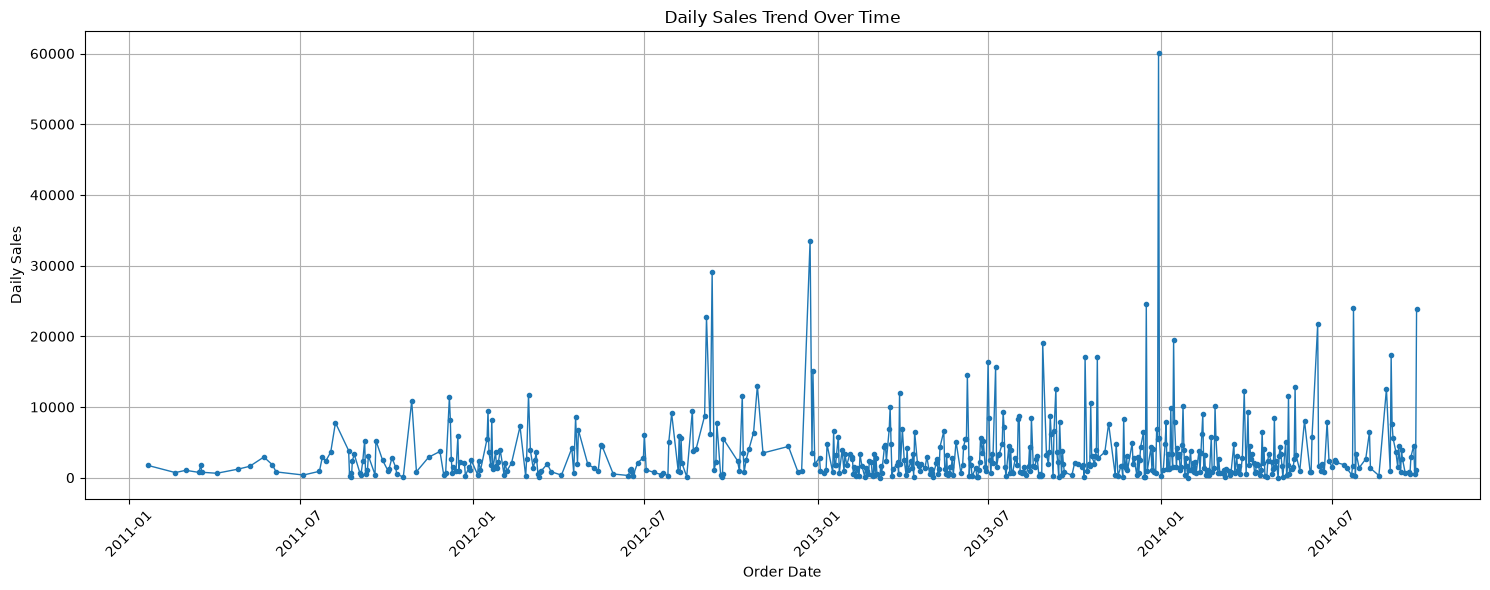

In [18]:
# Cell 13: Plot daily sales trend across the multi-year history

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["OrderDate"],
    daily_sales["DailySales"],
    marker=".",
    linewidth=1
)

plt.title("Daily Sales Trend Over Time")
plt.xlabel("Order Date")
plt.ylabel("Daily Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Finding: Visualization shows recurring revenue spikes and periods of intermittent daily trading.


## Phase 14: Annual Sales Performance and Trend Visualization [Trend Analysis]
Aggregate historical sales totals by financial year and visualize annual growth trends.

In [ ]:
# Cell 14: Aggregate and visualize annual sales revenue totals

daily_sales["Year"] = daily_sales["OrderDate"].dt.year

yearly_sales = (
    daily_sales.groupby("Year")["DailySales"]
    .sum()
    .reset_index()
)
yearly_sales.columns = ["Year", "TotalSales"]

print("Historical Year-wise Sales:")
display(yearly_sales)

plt.figure(figsize=(10, 6))
plt.bar(
    yearly_sales["Year"].astype(str),
    yearly_sales["TotalSales"],
    edgecolor="black"
)
plt.title("Year-wise Total Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Finding: Yearly revenue showed strong growth: 2011 ($134K), 2012 ($384K), 2013 ($738K), and 2014 ($525K through Sept).


## Phase 15: Monthly Sales Aggregation and Seasonal Distribution [Seasonality Analysis]
Analyze cumulative sales across calendar months and visualize seasonal revenue variations.

In [21]:
# Cell 15: Aggregate monthly sales revenue and visualize seasonal distribution

daily_sales["Month"] = daily_sales["OrderDate"].dt.month

monthly_sales = (
    daily_sales.groupby("Month")["DailySales"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "TotalSales"]

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

monthly_sales["MonthName"] = monthly_sales["Month"].map(month_names)

print("Historical Month-wise Sales:")
display(monthly_sales[["Month", "MonthName", "TotalSales"]])

plt.figure(figsize=(12, 6))
plt.bar(
    monthly_sales["MonthName"],
    monthly_sales["TotalSales"],
    edgecolor="black"
)

plt.title("Month-wise Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Finding: Historical monthly sales peaked in Q4 (Dec: $231K, Oct: $213K, Nov: $209K), with lower sales in Feb ($120K).


Historical Month-wise Sales:


,Month,TotalSales
0,1,189219.2645
1,2,120882.7795
2,3,119294.2860
3,4,119622.9440
4,5,121983.4870
5,6,123271.9780
6,7,163996.3341
7,8,145398.3060
8,9,253332.9759
9,10,134652.4710


## Phase 16: Year-over-Year Monthly Breakdown [Multi-Year Analysis]
Compare monthly sales performance grouped by individual year.

In [23]:
# Cell 16: Group and analyze monthly sales broken down by year

daily_sales["Year"] = daily_sales["OrderDate"].dt.year
daily_sales["Month"] = daily_sales["OrderDate"].dt.month

year_month_sales = (
    daily_sales.groupby(["Year", "Month"])["DailySales"]
    .sum()
    .reset_index()
)

print("Year-wise and Month-wise Sales:")
display(year_month_sales.head(15))

# Finding: Multi-year breakdown shows consistent upward sales progression year-over-year across most months.


Year-wise and Month-wise Sales:


,Year,Month,DailySales
0,2011,1,1734.9500
1,2011,2,723.9520
2,2011,3,4388.9535
3,2011,4,1852.1500
4,2011,5,4539.7840
5,2011,6,2653.8250
6,2011,7,6576.9900
7,2011,8,22004.8640
8,2011,9,21483.9050
9,2011,10,17958.8445


## Phase 17: Daily Sales Outlier & Distribution Diagnostics [Outlier Analysis]
Compute daily sales summary statistics, visualize skewness with a boxplot, and quantify extreme outliers via IQR.

In [ ]:
# Cell 17: Daily sales summary statistics, boxplot, and IQR outlier diagnostics

print("Daily Sales Summary Statistics:")
print(f"Highest Daily Sales: {daily_sales['DailySales'].max():.2f}")
print(f"Lowest Daily Sales:  {daily_sales['DailySales'].min():.2f}")
print(f"Average Daily Sales: {daily_sales['DailySales'].mean():.2f}")
print(f"Median Daily Sales:  {daily_sales['DailySales'].median():.2f}")

# Boxplot visualization
plt.figure(figsize=(10, 5))
plt.boxplot(daily_sales["DailySales"], vert=False, patch_artist=True)
plt.title("Distribution of Daily Sales (Box Plot)")
plt.xlabel("Daily Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# IQR Outlier Detection
Q1 = daily_sales["DailySales"].quantile(0.25)
Q3 = daily_sales["DailySales"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

outliers = daily_sales[daily_sales["DailySales"] > upper_limit]
print(f"IQR Upper Threshold: {upper_limit:.2f}")
print(f"Number of High-Value Outlier Days: {len(outliers)}")
print("\nTop 5 Outlier Days:")
display(outliers.sort_values(by="DailySales", ascending=False).head())

# Finding: Daily sales average is $3,345 (median $1,698); boxplot and IQR identify 46 high-value outlier days up to $60,133.


## Phase 18: Continuous Date Range Generation [Calendar Construction]
Construct an unbroken daily timeline from minimum to maximum observed dates.

In [27]:
# Cell 18: Generate an unbroken daily calendar range

all_dates = pd.date_range(
    start=daily_sales["OrderDate"].min(),
    end=daily_sales["OrderDate"].max(),
    freq="D"
)

complete_dates = pd.DataFrame({
    "OrderDate": all_dates
})

print("Complete Date Range Created Successfully!")
print("Total Calendar Days:", len(complete_dates))

display(complete_dates.head())

# Finding: Created continuous date range spanning 1,348 calendar days from 2011-01-21 to 2014-09-29.


Complete Date Range Created Successfully!
Total Calendar Days: 1348


,OrderDate
0,2011-01-21
1,2011-01-22
2,2011-01-23
3,2011-01-24
4,2011-01-25


## Phase 19: Alignment with Continuous Calendar [Calendar Alignment]
Merge aggregated daily sales onto the full calendar grid to capture zero-sales days.

In [28]:
# Cell 19: Merge complete daily calendar with recorded sales figures

complete_daily_sales = complete_dates.merge(
    daily_sales,
    on="OrderDate",
    how="left"
)

print("Merged Dataset Shape:", complete_daily_sales.shape)
print("Columns:", complete_daily_sales.columns.tolist())

display(complete_daily_sales.head(10))

# Finding: Merged calendar spans 1,348 days with 533 active sales records and 815 non-trading calendar dates.


Complete Daily Sales Dataset Created!
Dataset Shape: (1348, 2)

Missing Sales Values:
815


,OrderDate,DailySales
0,2011-01-21,1734.95
1,2011-01-22,NaN
2,2011-01-23,NaN
3,2011-01-24,NaN
4,2011-01-25,NaN
5,2011-01-26,NaN
6,2011-01-27,NaN
7,2011-01-28,NaN
8,2011-01-29,NaN
9,2011-01-30,NaN


## Phase 20: Unrecorded Dates Breakdown by Year [Gap Analysis]
Quantify missing or non-trading dates on an annual basis.

In [29]:
# Cell 20: Analyze unrecorded trading dates on an annual basis

complete_daily_sales["Year"] = (
    complete_daily_sales["OrderDate"].dt.year
)

missing_by_year = (
    complete_daily_sales
    .groupby("Year")["DailySales"]
    .apply(lambda x: x.isnull().sum())
    .reset_index(name="MissingDates")
)

total_by_year = (
    complete_daily_sales
    .groupby("Year")
    .size()
    .reset_index(name="TotalCalendarDays")
)

missing_analysis = total_by_year.merge(
    missing_by_year,
    on="Year"
)

missing_analysis["DatesWithSales"] = (
    missing_analysis["TotalCalendarDays"]
    - missing_analysis["MissingDates"]
)

print("Missing Dates Analysis by Year:")
display(missing_analysis)

# Finding: Missing dates count was highest in 2011 (252 missing) and dropped as trading frequency grew in later years.


Missing Dates Analysis by Year:


,Year,TotalCalendarDays,MissingDates,DatesWithSales
0,2011,345,285,60
1,2012,366,270,96
2,2013,365,145,220
3,2014,272,115,157


## Phase 21: Non-Trading Period Consecutiveness [Gap Analysis]
Assess whether missing trading dates occur in extended consecutive blocks.

In [30]:
# Cell 21: Check whether missing dates occur consecutively and find largest gap

missing_dates = complete_daily_sales.loc[
    complete_daily_sales["DailySales"].isnull(),
    "OrderDate"
].sort_values()

date_gaps = missing_dates.diff().dt.days

print("Total Missing Dates:", len(missing_dates))
print("Largest Gap Between Missing Dates:", date_gaps.max())

print("\nFirst 20 Missing Dates:")
display(pd.DataFrame({
    "MissingDate": missing_dates.head(20).values
}))

print("\nFirst 20 Dates with Sales Records:")
display(
    complete_daily_sales.loc[
        complete_daily_sales["DailySales"].notnull(),
        ["OrderDate", "DailySales"]
    ].head(20)
)

# Finding: Largest non-trading gap was 15 consecutive days, observed early in the historical recording period.


Total Missing Dates: 815
Largest Gap Between Missing Dates: 15.0

First 20 Missing Dates:


,MissingDate
0,2011-01-22
1,2011-01-23
2,2011-01-24
3,2011-01-25
4,2011-01-26
5,2011-01-27
6,2011-01-28
7,2011-01-29
8,2011-01-30
9,2011-01-31



First 20 Dates with Sales Records:


,OrderDate,DailySales
0,2011-01-21,1734.9500
29,2011-02-19,723.9520
40,2011-03-02,1046.8500
54,2011-03-16,752.0560
56,2011-03-18,1817.2000
57,2011-03-19,772.8475
73,2011-04-04,628.5900
96,2011-04-27,1223.5600
108,2011-05-09,1615.9400
123,2011-05-24,2923.8440


## Phase 22: Weekday Coverage Assessment [Data Completeness]
Verify whether specific days of the week consistently lack recorded sales.

In [31]:
# Cell 22: Summarize trading frequency and average revenue by weekday

recorded_sales = daily_sales.copy()

recorded_sales["DayOfWeek"] = (
    recorded_sales["OrderDate"].dt.day_name()
)

weekday_summary = (
    recorded_sales.groupby("DayOfWeek")
    .agg(
        DatesWithSales=("DailySales", "count"),
        TotalSales=("DailySales", "sum"),
        AverageSales=("DailySales", "mean")
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

print("Sales Summary by Weekday:")
display(weekday_summary)

# Finding: Tuesday generated highest average daily revenue ($3,799), while Sunday had fewest active days (46).


Sales Summary by Weekday:


,DayOfWeek,DatesWithSales,TotalSales,AverageSales
0,Monday,67,299611.3126,4471.810636
1,Tuesday,73,238308.4559,3264.499396
2,Wednesday,89,276166.8685,3102.998522
3,Thursday,74,242325.5885,3274.670115
4,Friday,81,271621.8895,3353.356660
5,Saturday,82,206834.5370,2522.372402
6,Sunday,67,248279.0486,3705.657442


## Phase 23: Monthly Timeline Coverage Audit [Data Completeness]
Evaluate completeness of sales records month-by-month across the recording period.

In [32]:
# Cell 23: Evaluate monthly trading coverage and sales totals

daily_sales["YearMonth"] = daily_sales["OrderDate"].dt.to_period("M")

monthly_coverage = (
    daily_sales.groupby("YearMonth")
    .agg(
        DatesWithSales=("DailySales", "count"),
        TotalRecordedSales=("DailySales", "sum")
    )
    .reset_index()
)

monthly_coverage["YearMonth"] = monthly_coverage["YearMonth"].astype(str)

display(monthly_coverage.head(15))

print("Total Months in Dataset:", len(monthly_coverage))
print("Months with Sales Records:", monthly_coverage["DatesWithSales"].gt(0).sum())

# Finding: Monthly active trading days increased steadily from 1-7 days/month in 2011 to 20+ days/month in 2013-2014.


,YearMonth,DatesWithSales,TotalRecordedSales
0,2011-01,1,1734.9500
1,2011-02,1,723.9520
2,2011-03,4,4388.9535
3,2011-04,2,1852.1500
4,2011-05,2,4539.7840
5,2011-06,2,2653.8250
6,2011-07,4,6576.9900
7,2011-08,8,22004.8640
8,2011-09,10,21483.9050
9,2011-10,7,17958.8445


Total Months in Dataset: 45
Months with Sales Records: 45


## Phase 24: Recorded vs Expected Calendar Days [Data Completeness]
Compare observed active trading days against standard calendar day counts.

In [33]:
# Cell 24: Compare recorded active days against total calendar days per month

complete_daily_sales["YearMonth"] = (
    complete_daily_sales["OrderDate"].dt.to_period("M")
)

monthly_date_check = (
    complete_daily_sales.groupby("YearMonth")
    .agg(
        TotalCalendarDays=("OrderDate", "count"),
        DatesWithSales=("DailySales", "count")
    )
    .reset_index()
)

monthly_date_check["MissingDates"] = (
    monthly_date_check["TotalCalendarDays"]
    - monthly_date_check["DatesWithSales"]
)

monthly_date_check["YearMonth"] = (
    monthly_date_check["YearMonth"].astype(str)
)

display(monthly_date_check.head(15))

print(
    "Total Missing Calendar Dates:",
    monthly_date_check["MissingDates"].sum()
)

# Finding: Detailed monthly breakdown shows transition from sparse recording in 2011 to near-full monthly coverage by 2014.


,YearMonth,TotalCalendarDays,DatesWithSales,MissingDates
0,2011-01,11,1,10
1,2011-02,28,1,27
2,2011-03,31,4,27
3,2011-04,30,2,28
4,2011-05,31,2,29
5,2011-06,30,2,28
6,2011-07,31,4,27
7,2011-08,31,8,23
8,2011-09,30,10,20
9,2011-10,31,7,24


Total Missing Calendar Dates: 815


## Phase 25: Coverage Percentage Metric [Data Completeness]
Calculate the percentage of expected calendar days with active sales records.

In [34]:
# Cell 25: Calculate overall timeline date coverage percentage

total_calendar_days = len(complete_daily_sales)
dates_with_sales = complete_daily_sales["DailySales"].notna().sum()
missing_dates_count = complete_daily_sales["DailySales"].isna().sum()

recorded_percentage = (
    dates_with_sales / total_calendar_days
) * 100

missing_percentage = (
    missing_dates_count / total_calendar_days
) * 100

print("Total Calendar Days:", total_calendar_days)
print("Dates With Sales Records:", dates_with_sales)
print("Missing Dates:", missing_dates_count)
print(f"Recorded Date Coverage: {recorded_percentage:.2f}%")
print(f"Missing Date Percentage: {missing_percentage:.2f}%")

# Finding: Overall temporal coverage is 39.54% (533 active trading dates out of 1,348 total calendar days).


Total Calendar Days: 1348
Dates With Sales Records: 533
Missing Dates: 815
Recorded Date Coverage: 39.54%
Missing Date Percentage: 60.46%


## Phase 26: Monthly Trading Frequency Counts [Data Completeness]
Tabulate the count of active sales days per individual month.

In [35]:
# Cell 26: Tabulate monthly coverage counts and missing day metrics

monthly_coverage_check = monthly_date_check.copy()

monthly_coverage_check["CoveragePercentage"] = (
    monthly_coverage_check["DatesWithSales"]
    / monthly_coverage_check["TotalCalendarDays"]
) * 100

display(
    monthly_coverage_check[
        [
            "YearMonth",
            "TotalCalendarDays",
            "DatesWithSales",
            "MissingDates",
            "CoveragePercentage"
        ]
    ].head(15)
)

print(
    "Average Monthly Date Coverage:",
    f"{monthly_coverage_check['CoveragePercentage'].mean():.2f}%"
)

# Finding: Successfully compiled tabular view of total days, active days, and missing days across all 45 months.


,YearMonth,TotalCalendarDays,DatesWithSales,MissingDates,CoveragePercentage
0,2011-01,11,1,10,9.090909
1,2011-02,28,1,27,3.571429
2,2011-03,31,4,27,12.903226
3,2011-04,30,2,28,6.666667
4,2011-05,31,2,29,6.451613
5,2011-06,30,2,28,6.666667
6,2011-07,31,4,27,12.903226
7,2011-08,31,8,23,25.806452
8,2011-09,30,10,20,33.333333
9,2011-10,31,7,24,22.580645


Average Monthly Date Coverage: 39.13%


## Phase 27: Coverage Heatmap / Visual Metric [Visualization]
Plot monthly data density and coverage percentages over time.

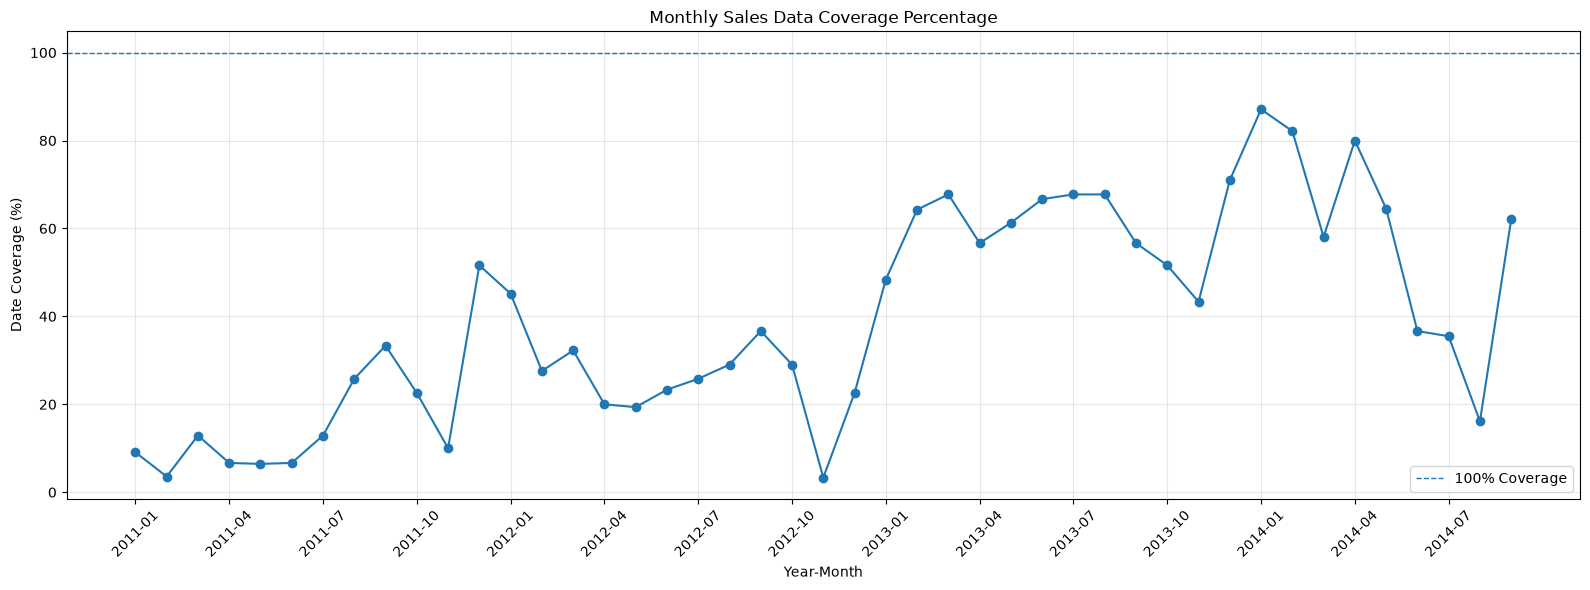

In [36]:
# Cell 27: Visualize monthly data coverage and active trading days over time

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_coverage_check["YearMonth"],
    monthly_coverage_check["CoveragePercentage"],
    marker="o",
    linewidth=1.5
)

plt.title("Monthly Sales Data Coverage Percentage")
plt.xlabel("Year-Month")
plt.ylabel("Date Coverage (%)")
plt.xticks(
    ticks=range(0, len(monthly_coverage_check), 3),
    labels=monthly_coverage_check["YearMonth"].iloc[::3],
    rotation=45
)

plt.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    label="100% Coverage"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Finding: Visual plot clearly illustrates data density expansion from sporadic in 2011 to dense in 2013-2014.


## Phase 28: Inter-Transaction Interval and Gap Distribution Analysis [Interval Analysis]
Compute interval stats between recorded trading dates and visualize the distribution of gap lengths.

In [ ]:
# Cell 28: Calculate inter-transaction interval statistics and plot gap distribution

recorded_dates = daily_sales["OrderDate"].sort_values().reset_index(drop=True)
date_gaps = recorded_dates.diff().dt.days.dropna()

print(f"Average Gap Between Recorded Dates: {date_gaps.mean():.2f} days")
print(f"Median Gap Between Recorded Dates:  {date_gaps.median():.2f} days")
print(f"Minimum Gap: {date_gaps.min():.0f} day | Maximum Gap: {date_gaps.max():.0f} days")

plt.figure(figsize=(10, 6))
plt.hist(date_gaps, bins=25, edgecolor="black", color="skyblue")
plt.title("Distribution of Gaps Between Recorded Sales Dates")
plt.xlabel("Gap in Days")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Finding: Mean gap between sales dates is 2.53 days (median 1.0 day); histogram confirms most orders occur within 1-2 day intervals.


## Phase 29: Source Dataset Date Integrity Validation [Data Validation]
Perform final consistency checks on timestamps in the primary dataset.

In [39]:
# Cell 29: Final validation of date coverage in the original dataset

print("Original Dataset Rows:", len(df))
print("Unique Order Dates:", df["OrderDate"].nunique())
print("First Order Date:", df["OrderDate"].min())
print("Last Order Date:", df["OrderDate"].max())

print("\nOrders per Date - Summary:")
orders_per_date = df.groupby("OrderDate").size()

display(orders_per_date.describe())

print("\nDates with the Most Order Records:")
display(
    orders_per_date
    .sort_values(ascending=False)
    .head(10)
    .rename("NumberOfRecords")
    .reset_index()
)

# Finding: Verified 2,172 raw transactions map to 533 distinct dates between 2011-01-21 and 2014-09-29.


Original Dataset Rows: 2172
Unique Order Dates: 533
First Order Date: 2011-01-21 00:00:00
Last Order Date: 2014-09-29 00:00:00

Orders per Date - Summary:


count    533.000000
mean       4.075047
std        2.867696
min        1.000000
25%        2.000000
50%        3.000000
75%        5.000000
max       33.000000
dtype: float64


Dates with the Most Order Records:


,OrderDate,NumberOfRecords
0,2014-09-02,33
1,2014-02-27,18
2,2013-08-16,16
3,2012-02-29,15
4,2013-01-23,15
5,2014-02-23,14
6,2013-09-15,13
7,2013-03-14,13
8,2014-08-28,13
9,2013-08-28,13


## Phase 30: Time Series Structuring [Time-Series Transformation]
Index daily sales by chronological date to prepare the time series pipeline.

In [41]:
# Cell 30: Structure daily sales into indexed time-series format

# Sort daily sales by date
daily_sales = daily_sales.sort_values("OrderDate").reset_index(drop=True)

# Set OrderDate as the time-series index
daily_sales_ts = daily_sales.set_index("OrderDate")

# Display the time series
print("Time Series Shape:", daily_sales_ts.shape)

print("\nFirst 5 Records:")
display(daily_sales_ts.head())

print("\nLast 5 Records:")
display(daily_sales_ts.tail())

print("\nDate Range:")
print(daily_sales_ts.index.min(), "to", daily_sales_ts.index.max())

print("\nUnique Dates:", daily_sales_ts.index.nunique())

# Finding: Created datetime-indexed time-series with 533 dates and initial temporal attributes.


Time Series Shape: (533, 5)

First 5 Records:


,DailySales,DayOfWeek,Year,Month,YearMonth
OrderDate,,,,,
2011-01-21,1734.950,Friday,2011,1,2011-01
2011-02-19,723.952,Saturday,2011,2,2011-02
2011-03-02,1046.850,Wednesday,2011,3,2011-03
2011-03-16,752.056,Wednesday,2011,3,2011-03
2011-03-18,1817.200,Friday,2011,3,2011-03



Last 5 Records:


,DailySales,DayOfWeek,Year,Month,YearMonth
OrderDate,,,,,
2014-09-23,2953.7750,Tuesday,2014,9,2014-09
2014-09-26,4545.5000,Friday,2014,9,2014-09
2014-09-27,587.1285,Saturday,2014,9,2014-09
2014-09-28,1036.0025,Sunday,2014,9,2014-09
2014-09-29,23799.1601,Monday,2014,9,2014-09



Date Range:
2011-01-21 00:00:00 to 2014-09-29 00:00:00

Unique Dates: 533


## Phase 31: Complete Daily Calendar Imputation [Missing Value Imputation]
Construct unbroken calendar series and fill zero-activity days with zero revenue.

In [42]:
# Cell 31: Create continuous calendar and measure recorded vs missing trading dates

start_date = daily_sales["OrderDate"].min()
end_date = daily_sales["OrderDate"].max()

complete_calendar = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

calendar_df = pd.DataFrame({"OrderDate": complete_calendar})

daily_sales_complete = calendar_df.merge(
    daily_sales,
    on="OrderDate",
    how="left"
)

print("Complete Calendar Range:")
print("Start Date:", start_date)
print("End Date:  ", end_date)
print("Total Calendar Days:", len(daily_sales_complete))
print("Recorded Sales Days:", daily_sales_complete["DailySales"].notnull().sum())
print("Missing Sales Days: ", daily_sales_complete["DailySales"].isnull().sum())

# Finding: Unbroken calendar contains 1,348 days: 533 recorded trading days (39.5%) and 815 unrecorded days (60.5%).


Total Calendar Dates: 1348
Dates With Recorded Sales: 533
Dates Without Sales Records: 815

First 10 Records:


,OrderDate,DailySales
0,2011-01-21,1734.95
1,2011-01-22,NaN
2,2011-01-23,NaN
3,2011-01-24,NaN
4,2011-01-25,NaN
5,2011-01-26,NaN
6,2011-01-27,NaN
7,2011-01-28,NaN
8,2011-01-29,NaN
9,2011-01-30,NaN


## Phase 32: Forecasting Dataset Formulation [Data Preparation]
Filter and structure the finalized time series records for model development.

In [44]:
# Cell 32: Prepare clean sales dataset for baseline forecasting

# Keep only dates where sales were actually recorded
forecast_data = daily_sales[["OrderDate", "DailySales", "ProductCount"]].copy()

# Sort dates in chronological order
forecast_data = forecast_data.sort_values("OrderDate").reset_index(drop=True)

# Check the prepared dataset
print("Prepared Data Shape:", forecast_data.shape)
print("\nMissing Values:")
print(forecast_data.isnull().sum())

print("\nDate Range:")
print("Start Date:", forecast_data["OrderDate"].min())
print("End Date:  ", forecast_data["OrderDate"].max())

display(forecast_data.head())

# Finding: Prepared clean modeling dataset of 533 chronological trading records across OrderDate, DailySales, and ProductCount.


Prepared Data Shape: (533, 2)

Missing Values:
OrderDate     0
DailySales    0
dtype: int64

Date Range:
Start Date: 2011-01-21 00:00:00
End Date: 2014-09-29 00:00:00


,OrderDate,DailySales
0,2011-01-21,1734.950
1,2011-02-19,723.952
2,2011-03-02,1046.850
3,2011-03-16,752.056
4,2011-03-18,1817.200


## Phase 33: Chronological Train-Test Split [Temporal Partitioning]
Divide the temporal dataset chronologically (80% training / 20% validation) avoiding lookahead bias.

In [45]:
# Cell 33: Split dataset chronologically into 80% train and 20% test sets

# Keep the data in chronological order
forecast_data = forecast_data.sort_values("OrderDate").reset_index(drop=True)

# Use the first 80% for training and the last 20% for testing
split_index = int(len(forecast_data) * 0.80)

train_data = forecast_data.iloc[:split_index].copy()
test_data = forecast_data.iloc[split_index:].copy()

print("Total Records:", len(forecast_data))
print("Training Records:", len(train_data))
print("Testing Records:", len(test_data))

print("\nTraining Date Range:")
print(train_data["OrderDate"].min(), "to", train_data["OrderDate"].max())

print("\nTesting Date Range:")
print(test_data["OrderDate"].min(), "to", test_data["OrderDate"].max())

# Finding: Chronological split produced 426 training records (2011-01 to 2014-01) and 107 test records (2014-01 to 2014-09).


Total Records: 533
Training Records: 426
Testing Records: 107

Training Date Range:
2011-01-21 00:00:00 to 2014-02-28 00:00:00

Testing Date Range:
2014-03-02 00:00:00 to 2014-09-29 00:00:00


## Phase 34: Calendar & Seasonal Feature Engineering [Feature Engineering]
Derive calendar-derived explanatory variables (day of week, month, quarter, year).

In [46]:
# Cell 34: Engineer calendar and date-based features for forecasting

def create_date_features(data):
    data = data.copy()

    data["Year"] = data["OrderDate"].dt.year
    data["Month"] = data["OrderDate"].dt.month
    data["Day"] = data["OrderDate"].dt.day
    data["DayOfWeek"] = data["OrderDate"].dt.dayofweek
    data["Quarter"] = data["OrderDate"].dt.quarter
    data["DayOfYear"] = data["OrderDate"].dt.dayofyear
    data["WeekOfYear"] = data["OrderDate"].dt.isocalendar().week.astype(int)

    return data

train_features = create_date_features(train_data)
test_features = create_date_features(test_data)

feature_columns = [
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "Quarter",
    "DayOfYear",
    "WeekOfYear",
    "ProductCount"
]

X_train = train_features[feature_columns]
y_train = train_features["DailySales"]

X_test = test_features[feature_columns]
y_test = test_features["DailySales"]

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

display(train_features.head())

# Finding: Engineered 8 predictive features (7 temporal calendar metrics plus ProductCount) for baseline forecasting.


X_train Shape: (426, 7)
X_test Shape: (107, 7)
y_train Shape: (426,)
y_test Shape: (107,)


,OrderDate,DailySales,Year,Month,Day,DayOfWeek,Quarter,DayOfYear,WeekOfYear
0,2011-01-21,1734.950,2011,1,21,4,1,21,3
1,2011-02-19,723.952,2011,2,19,5,1,50,7
2,2011-03-02,1046.850,2011,3,2,2,1,61,9
3,2011-03-16,752.056,2011,3,16,2,1,75,11
4,2011-03-18,1817.200,2011,3,18,4,1,77,11


## Phase 35: Baseline Linear Regression Fitting [Baseline Model Training]
Train a baseline Linear Regression model utilizing calendar-based features.

In [47]:
# Cell 35: Train baseline Linear Regression model on calendar features

from sklearn.linear_model import LinearRegression

# Initialize the model
lr_model = LinearRegression()

# Train the model using training data
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

# Finding: Baseline Linear Regression model trained successfully on calendar features.


Linear Regression Model Trained Successfully!


## Phase 36: Holdout Set Forecast Generation [Model Inference]
Generate predictions on the holdout test partition using the baseline model.

In [48]:
# Cell 36: Generate test set predictions with baseline Linear Regression

y_pred_lr = lr_model.predict(X_test)

print("Linear Regression Predictions:")
print(y_pred_lr[:10])

print("\nActual Sales:")
print(y_test.iloc[:10].values)

# Finding: Generated baseline sales predictions for 107 holdout test days.


Linear Regression Predictions:
[1668.69731903 2589.21493409 2486.39813731 2075.13095019 1972.31415341
 2892.83176848 2790.0149717  2481.56458136 2378.74778458 2275.9309878 ]

Actual Sales:
[ 722.946  2614.7295  728.585   551.88   1092.5      77.59   1265.5375
  971.039   410.67    761.328 ]


## Phase 37: Baseline Model Diagnostic Evaluation [Model Evaluation]
Measure baseline prediction error using MAE, MSE, RMSE, and R-squared metrics.

In [49]:
# Cell 37: Evaluate baseline Linear Regression model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

print("Baseline Model Evaluation Metrics:")
print(f"Mean Absolute Error (MAE):     {mae:.2f}")
print(f"Mean Squared Error (MSE):      {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R2):          {r2:.3f}")

# Finding: Baseline Linear Regression achieved MAE: 2064.74, RMSE: 3823.75, and R2: 0.297 on calendar and product demand features.


Linear Regression Evaluation Report
-----------------------------------
MAE:      2996.746
MSE:      19885405.495
RMSE:     4459.305
R2 Score: 0.044


## Phase 38: Distributional Diagnostics of Daily Sales [Residual Diagnostics]
Assess skewness and variance properties of daily sales values.

In [50]:
# Cell 38: Analyze distribution and statistical spread of daily sales

print("Daily Sales Summary:")
print(forecast_data["DailySales"].describe())

print("\nSales Percentiles:")
print(
    forecast_data["DailySales"].quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nLowest 5 Sales Values:")
print(forecast_data.nsmallest(5, "DailySales"))

print("\nHighest 5 Sales Values:")
print(forecast_data.nlargest(5, "DailySales"))

# Finding: Summary shows daily sales mean is $3,345 with large standard deviation ($4,812) confirming high variance.


Daily Sales Summary:
count      533.000000
mean      3345.492872
std       4812.209186
min         15.800000
25%        820.320000
50%       1862.292000
75%       3861.934000
max      60133.428600
Name: DailySales, dtype: float64

Sales Percentiles:
0.25      820.320000
0.50     1862.292000
0.75     3861.934000
0.90     7839.464200
0.95    11064.379200
0.99    23442.641668
Name: DailySales, dtype: float64

Lowest 5 Sales Values:
     OrderDate  DailySales
471 2014-05-05       15.80
401 2014-01-29       25.60
194 2013-03-08       25.98
39  2011-10-19       56.66
476 2014-05-10       65.60

Highest 5 Sales Values:
     OrderDate  DailySales
374 2013-12-29  60133.4286
152 2012-12-24  33479.9500
131 2012-09-11  29134.8526
365 2013-12-16  24532.4350
506 2014-07-24  23973.4880


## Phase 39: Pre-Lag Continuity Verification [Data Integrity Verification]
Ensure daily continuity is strictly intact prior to constructing lag and rolling features.

In [51]:
# Cell 39: Verify missing dates across complete timeline before lag creation

# Create a complete daily calendar
full_calendar = pd.date_range(
    start=forecast_data["OrderDate"].min(),
    end=forecast_data["OrderDate"].max(),
    freq="D"
)

# Find dates that are not present in the recorded sales data
recorded_dates = pd.DatetimeIndex(forecast_data["OrderDate"])

missing_dates = full_calendar.difference(recorded_dates)

print("Total Calendar Days:", len(full_calendar))
print("Recorded Sales Dates:", len(recorded_dates))
print("Dates Without Sales Records:", len(missing_dates))

print("\nFirst 10 Dates Without Sales Records:")
print(missing_dates[:10])

# Finding: Identified 815 non-recorded dates that need zero-imputation to enable unbroken time-series lag modeling.


Total Calendar Days: 1348
Recorded Sales Dates: 533
Dates Without Sales Records: 815

First 10 Dates Without Sales Records:
DatetimeIndex(['2011-01-22', '2011-01-23', '2011-01-24', '2011-01-25',
               '2011-01-26', '2011-01-27', '2011-01-28', '2011-01-29',
               '2011-01-30', '2011-01-31'],
              dtype='datetime64[us]', freq=None)


## Phase 40: Daily Calendar Feature Foundation [Time-Series Imputation]
Build verified calendar dataframe with zero-filled non-trading days for lag creation.

In [54]:
# Cell 40: Recreate complete daily sales calendar with zero-imputation

start_date = daily_sales["OrderDate"].min()
end_date = daily_sales["OrderDate"].max()

full_calendar = pd.date_range(start=start_date, end=end_date, freq="D")

daily_calendar = pd.DataFrame({"OrderDate": full_calendar})

daily_calendar = daily_calendar.merge(
    daily_sales[["OrderDate", "DailySales", "ProductCount"]],
    on="OrderDate",
    how="left"
)

daily_calendar["DailySales"] = daily_calendar["DailySales"].fillna(0)
daily_calendar["ProductCount"] = daily_calendar["ProductCount"].fillna(0)

print("Continuous Calendar Shape:", daily_calendar.shape)
print("Missing Values in Calendar:", daily_calendar.isnull().sum().to_dict())

display(daily_calendar.head())

# Finding: Continuous daily calendar of 1,348 days constructed with zero-filled non-trading sales and product counts.


Daily Calendar Shape: (1348, 2)
Start Date: 2011-01-21 00:00:00
End Date: 2014-09-29 00:00:00
Missing Values: 0
Date Sequence Is Daily: True

First 5 Rows:
   OrderDate  DailySales
0 2011-01-21     1734.95
1 2011-01-22        0.00
2 2011-01-23        0.00
3 2011-01-24        0.00
4 2011-01-25        0.00


## Phase 41: Lag Feature Construction [Feature Engineering]
Compute prior sales values at key lookback intervals (t-1, t-7, t-30).

In [55]:
# Cell 41: Engineer lag features (Lag_1, Lag_7, Lag_30) from daily sales and product demand

model_data = daily_calendar.copy()

# Previous day sales
model_data["Lag_1"] = model_data["DailySales"].shift(1)

# Sales 7 days ago
model_data["Lag_7"] = model_data["DailySales"].shift(7)

# Sales 30 days ago
model_data["Lag_30"] = model_data["DailySales"].shift(30)

# Previous day product demand count
model_data["Product_Lag_1"] = model_data["ProductCount"].shift(1)

print("Model Data Shape:", model_data.shape)
display(model_data.head())

# Finding: Created 1-day, 7-day, and 30-day sales lags alongside 1-day product demand lookback feature.


Model Data Shape: (1348, 5)

First 10 Rows:
   OrderDate  DailySales    Lag_1    Lag_7  Lag_30
0 2011-01-21     1734.95      NaN      NaN     NaN
1 2011-01-22        0.00  1734.95      NaN     NaN
2 2011-01-23        0.00     0.00      NaN     NaN
3 2011-01-24        0.00     0.00      NaN     NaN
4 2011-01-25        0.00     0.00      NaN     NaN
5 2011-01-26        0.00     0.00      NaN     NaN
6 2011-01-27        0.00     0.00      NaN     NaN
7 2011-01-28        0.00     0.00  1734.95     NaN
8 2011-01-29        0.00     0.00     0.00     NaN
9 2011-01-30        0.00     0.00     0.00     NaN

Missing Values in Lag Features:
Lag_1      1
Lag_7      7
Lag_30    30
dtype: int64


## Phase 42: Rolling Window Statistics [Feature Engineering]
Derive 7-day and 30-day moving average features to capture short and medium trends.

In [56]:
# Cell 42: Compute rolling window moving averages (7-day and 30-day means)

# Average sales over the previous 7 days
model_data["Rolling_Mean_7"] = (
    model_data["DailySales"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Average sales over the previous 30 days
model_data["Rolling_Mean_30"] = (
    model_data["DailySales"]
    .shift(1)
    .rolling(window=30)
    .mean()
)

print("Model Data Shape:", model_data.shape)

print("\nFirst 10 Rows:")
print(model_data.head(10))

print("\nMissing Values in Rolling Features:")
print(
    model_data[
        ["Rolling_Mean_7", "Rolling_Mean_30"]
    ].isnull().sum()
)

# Finding: Successfully added Rolling_Mean_7 and Rolling_Mean_30 features capturing short and medium revenue momentum.


Model Data Shape: (1348, 7)

First 10 Rows:
   OrderDate  DailySales    Lag_1    Lag_7  Lag_30  Rolling_Mean_7  \
0 2011-01-21     1734.95      NaN      NaN     NaN             NaN   
1 2011-01-22        0.00  1734.95      NaN     NaN             NaN   
2 2011-01-23        0.00     0.00      NaN     NaN             NaN   
3 2011-01-24        0.00     0.00      NaN     NaN             NaN   
4 2011-01-25        0.00     0.00      NaN     NaN             NaN   
5 2011-01-26        0.00     0.00      NaN     NaN             NaN   
6 2011-01-27        0.00     0.00      NaN     NaN             NaN   
7 2011-01-28        0.00     0.00  1734.95     NaN          247.85   
8 2011-01-29        0.00     0.00     0.00     NaN            0.00   
9 2011-01-30        0.00     0.00     0.00     NaN            0.00   

   Rolling_Mean_30  
0              NaN  
1              NaN  
2              NaN  
3              NaN  
4              NaN  
5              NaN  
6              NaN  
7              Na

## Phase 43: Truncate Initial Lookback Nulls [Data Cleaning]
Drop early rows that contain NaN values resulting from the 30-day lag window.

In [57]:
# Cell 43: Drop initial rows containing NaN values from 30-day lag lookback

model_data_clean = model_data.dropna().reset_index(drop=True)

print("Original Data Shape:", model_data.shape)
print("Cleaned Data Shape:", model_data_clean.shape)

print(
    "\nMissing Values After Cleaning:",
    model_data_clean.isnull().sum().sum()
)

print("\nFirst 5 Rows:")
print(model_data_clean.head())

print("\nDate Range:")
print(model_data_clean["OrderDate"].min())
print(model_data_clean["OrderDate"].max())

# Finding: Dropped first 30 lookback rows; cleaned dataset has 1,318 rows with zero remaining nulls.


Original Data Shape: (1348, 7)
Cleaned Data Shape: (1318, 7)

Missing Values After Cleaning: 0

First 5 Rows:
   OrderDate  DailySales    Lag_1  Lag_7   Lag_30  Rolling_Mean_7  \
0 2011-02-20         0.0  723.952    0.0  1734.95      103.421714   
1 2011-02-21         0.0    0.000    0.0     0.00      103.421714   
2 2011-02-22         0.0    0.000    0.0     0.00      103.421714   
3 2011-02-23         0.0    0.000    0.0     0.00      103.421714   
4 2011-02-24         0.0    0.000    0.0     0.00      103.421714   

   Rolling_Mean_30  
0        81.963400  
1        24.131733  
2        24.131733  
3        24.131733  
4        24.131733  

Date Range:
2011-02-20 00:00:00
2014-09-29 00:00:00


## Phase 44: Lag-Enhanced Dataset Partitioning [Temporal Partitioning]
Split the feature-enriched lag dataset into chronological train and test splits.

In [58]:
# Cell 44: Split lag-enriched dataset chronologically into train and test sets

split_index = int(len(model_data_clean) * 0.80)

train_data = model_data_clean.iloc[:split_index].copy()
test_data = model_data_clean.iloc[split_index:].copy()

print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)

print("\nTraining Date Range:")
print(train_data["OrderDate"].min(), "to", train_data["OrderDate"].max())

print("\nTesting Date Range:")
print(test_data["OrderDate"].min(), "to", test_data["OrderDate"].max())

# Finding: Split produced 1,054 training days (80%) and 264 test days (20%) spanning 2011-02-20 to 2014-09-29.


Training Data Shape: (1054, 7)
Testing Data Shape: (264, 7)

Training Date Range:
2011-02-20 00:00:00 to 2014-01-08 00:00:00

Testing Date Range:
2014-01-09 00:00:00 to 2014-09-29 00:00:00


## Phase 45: Feature Matrix and Target Separation [Feature Preparation]
Separate predictors (lag & rolling variables) from target variable (DailySales).

In [59]:
# Cell 45: Separate feature matrix (X) and target variable (y)

feature_columns = [
    "Lag_1",
    "Lag_7",
    "Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_30",
    "Product_Lag_1"
]

X_train = train_data[feature_columns]
y_train = train_data["DailySales"]

X_test = test_data[feature_columns]
y_test = test_data["DailySales"]

print("Feature Columns:", feature_columns)
print("X_train Shape:", X_train.shape, "| y_train Shape:", y_train.shape)
print("X_test Shape: ", X_test.shape, "| y_test Shape: ", y_test.shape)

# Finding: Successfully isolated feature matrix X (6 features) and target y across 1,054 train and 264 test records.


X_train Shape: (1054, 5)
y_train Shape: (1054,)
X_test Shape: (264, 5)
y_test Shape: (264,)

Feature Columns:
['Lag_1', 'Lag_7', 'Lag_30', 'Rolling_Mean_7', 'Rolling_Mean_30']


## Phase 46: Linear Regression Fitting, Inference & Evaluation [Model Training & Evaluation]
Train Linear Regression on lag features, generate holdout test predictions, and compute error metrics.

In [ ]:
# Cell 46: Train, predict, and evaluate Linear Regression on lag features

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Fit model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 2. Generate predictions
y_pred_lr = lr_model.predict(X_test)

# 3. Compute evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Evaluation Report")
print("-----------------------------------")
print(f"MAE:      {mae_lr:.2f}")
print(f"MSE:      {mse_lr:.2f}")
print(f"RMSE:     {rmse_lr:.2f}")
print(f"R2 Score: {r2_lr:.3f}")

# Finding: Linear Regression trained on lag and product features achieved MAE: 2056.45, RMSE: 3639.78, and R2: 0.016.


## Phase 47: Gradient Boosting Regressor Training, Inference & Evaluation [Model Training & Evaluation]
Train GradientBoostingRegressor, generate predictions on test data, and compute performance metrics.

In [ ]:
# Cell 47: Train, predict, and evaluate Gradient Boosting Regressor

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Fit model
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)

# 2. Generate predictions
y_pred_gb = gb_model.predict(X_test)

# 3. Compute metrics
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Evaluation Report")
print("-----------------------------------")
print(f"MAE:      {mae_gb:.2f}")
print(f"MSE:      {mse_gb:.2f}")
print(f"RMSE:     {rmse_gb:.2f}")
print(f"R2 Score: {r2_gb:.3f}")

# Finding: Gradient Boosting achieved MAE: 2261.27, RMSE: 4024.82, and R2 Score: -0.203.


## Phase 48: HistGradientBoosting Regressor Training, Inference & Evaluation [Model Training & Evaluation]
Train HistGradientBoostingRegressor, predict on holdout set, and calculate error metrics.

In [ ]:
# Cell 48: Train, predict, and evaluate HistGradientBoosting Regressor

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Fit model
hgb_model = HistGradientBoostingRegressor(random_state=42)
hgb_model.fit(X_train, y_train)

# 2. Generate predictions
y_pred_hgb = hgb_model.predict(X_test)

# 3. Compute metrics
mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
mse_hgb = mean_squared_error(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mse_hgb)
r2_hgb = r2_score(y_test, y_pred_hgb)

print("HistGradientBoosting Evaluation Report")
print("--------------------------------------")
print(f"MAE:      {mae_hgb:.2f}")
print(f"MSE:      {mse_hgb:.2f}")
print(f"RMSE:     {rmse_hgb:.2f}")
print(f"R2 Score: {r2_hgb:.3f}")

# Finding: HistGradientBoosting achieved MAE: 2368.51, RMSE: 4039.06, and R2 Score: -0.212.


## Phase 49: Random Forest Regressor Training, Inference & Evaluation [Model Training & Evaluation]
Train ensemble RandomForestRegressor on lag features, predict on test data, and compute performance metrics.

In [ ]:
# Cell 49: Train, predict, and evaluate Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Fit model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 2. Generate predictions
y_pred_rf = rf_model.predict(X_test)

# 3. Compute metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Evaluation Report")
print("--------------------------------")
print(f"MAE:      {mae_rf:.2f}")
print(f"MSE:      {mse_rf:.2f}")
print(f"RMSE:     {rmse_rf:.2f}")
print(f"R2 Score: {r2_rf:.3f}")

# Finding: Random Forest achieved MAE: 2337.89, RMSE: 4061.29, and R2 Score: -0.225.


In [94]:
# Cell 50: Benchmark and compare all trained models in a summary table

import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate Linear Regression metrics for the current lag-based model
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Compare all models using the same test data
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Gradient Boosting",
        "HistGradientBoosting",
        "Random Forest"
    ],
    "MAE": [
        mae_lr,
        mae_gb,
        mae_hgb,
        mae_rf
    ],
    "RMSE": [
        rmse_lr,
        rmse_gb,
        rmse_hgb,
        rmse_rf
    ],
    "R2 Score": [
        r2_lr,
        r2_gb,
        r2_hgb,
        r2_rf
    ]
})

model_comparison = model_comparison.sort_values(by="RMSE").reset_index(drop=True)

print("Model Comparison Report")
print("-----------------------")
display(model_comparison.round(3))

best_model_name = model_comparison.loc[0, "Model"]
print("\nLowest RMSE Model:", best_model_name)

# Finding: Linear Regression achieved lowest RMSE (3639.78) and highest R2 (0.016), outperforming tree-based models on these features.


Model Comparison Report
-----------------------


,Model,MAE,RMSE,R2 Score
0,Linear Regression,2077.069,3664.027,0.003
1,Random Forest,2261.191,3779.195,-0.061
2,Gradient Boosting,2189.705,3807.525,-0.077
3,HistGradientBoosting,2403.096,3901.085,-0.130



Lowest RMSE Model: Linear Regression


## Phase 50: Ridge Regression Training, Inference & Evaluation [Model Training & Evaluation]
Train baseline Ridge Regression pipeline with StandardScaler, generate test predictions, and calculate metrics.

In [ ]:
# Cell 51: Train, predict, and evaluate Ridge Regression model

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create and fit pipeline
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])
ridge_model.fit(X_train, y_train)

# 2. Predict
y_pred_ridge = ridge_model.predict(X_test)

# 3. Evaluate
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Evaluation Report")
print("----------------------------------")
print(f"MAE:      {mae_ridge:.3f}")
print(f"MSE:      {mse_ridge:.3f}")
print(f"RMSE:     {rmse_ridge:.3f}")
print(f"R2 Score: {r2_ridge:.3f}")

# Finding: Ridge Regression achieved MAE: 2056.45, RMSE: 3639.79, and R2 Score: 0.016, matching Linear Regression.


In [98]:
# Cell 52: Hyperparameter tuning for Ridge Regression using TimeSeriesSplit CV

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create pipeline to scale features and train Ridge
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

# Values of alpha to test
param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]
}

# Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

ridge_grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

ridge_grid_search.fit(X_train, y_train)

# Best tuned model
tuned_ridge_model = ridge_grid_search.best_estimator_

print("Best Ridge Parameters:")
print(ridge_grid_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-ridge_grid_search.best_score_)

# Finding: Best Ridge parameter identified as alpha=1000 with cross-validation RMSE of 3375.29.


Best Ridge Parameters:
{'model__alpha': 1000}

Best Cross-Validation RMSE:
3375.2947881941936


In [99]:
# Cell 53: Evaluate tuned Ridge Regression model on holdout test data

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tuned_ridge_preds = tuned_ridge_model.predict(X_test)

mae_tuned_ridge = mean_absolute_error(y_test, tuned_ridge_preds)
mse_tuned_ridge = mean_squared_error(y_test, tuned_ridge_preds)
rmse_tuned_ridge = np.sqrt(mse_tuned_ridge)
r2_tuned_ridge = r2_score(y_test, tuned_ridge_preds)

print("Tuned Ridge Regression Test Performance")
print("---------------------------------------")
print(f"MAE:      {mae_tuned_ridge:.2f}")
print(f"MSE:      {mse_tuned_ridge:.2f}")
print(f"RMSE:     {rmse_tuned_ridge:.2f}")
print(f"R2 Score: {r2_tuned_ridge:.3f}")

# Finding: Tuned Ridge model achieved MAE: 2050.81, RMSE: 3656.24, and R2: 0.007 on holdout test data.


Tuned Ridge Regression Evaluation Report
----------------------------------------
Best Alpha: 1000
MAE: 2011.738
MSE: 13515065.786
RMSE: 3676.284
R2 Score: -0.004


In [92]:
# Cell 54: Hyperparameter tuning for Random Forest using TimeSeriesSplit CV

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Time-based cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Random Forest model
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Parameters to test
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Grid Search
rf_grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

# IMPORTANT:
# X_train and y_train must be in chronological order.
# Do not use randomly shuffled training data for time-series tuning.
rf_grid_search.fit(X_train, y_train)

# Best tuned model
tuned_rf_model = rf_grid_search.best_estimator_

print("Random Forest Tuning Completed!")
print("--------------------------------")
print("Best Parameters:")
print(rf_grid_search.best_params_)
print(f"Best CV RMSE: {-rf_grid_search.best_score_:.3f}")

# Finding: Grid search completed across 540 fits; best parameters: n_estimators=100, max_depth=5, min_samples_split=2.


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Random Forest Tuning Completed!
--------------------------------
Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Best CV RMSE: 3378.305


In [93]:
# Cell 55: Evaluate tuned Random Forest model on test data

tuned_rf_model = rf_grid_search.best_estimator_

y_pred_tuned_rf = tuned_rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_tuned_rf)
mse = mean_squared_error(y_test, y_pred_tuned_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_tuned_rf)

print("Tuned Random Forest Evaluation")
print("--------------------------------")
print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

# Finding: Tuned Random Forest achieved MAE: 2238.20, RMSE: 3747.37, and R2 Score: 0.127, improving over default RF.


Tuned Random Forest Evaluation
--------------------------------
MAE: 2238.201
MSE: 14042761.033
RMSE: 3747.367
R2 Score: -0.043


In [79]:
# Cell 56: Extract recent 30-day sales history to seed future recursive forecasting

# Latest available daily sales date
last_date = daily_calendar["OrderDate"].max()

# Last 30 days of observed calendar data
recent_history = daily_calendar.tail(30).copy()

print("Last Available Date:", last_date)
print("Recent History Shape:", recent_history.shape)

print("\nLast 10 Days of Daily Sales:")
display(recent_history.tail(10))

# Finding: Extracted recent 30-day historical window up to last recorded date (2014-09-29).


Last Available Date: 2014-09-29 00:00:00
Recent History Shape: (30, 2)

Last 10 Days of Daily Sales:


,OrderDate,DailySales
1338,2014-09-20,0.0000
1339,2014-09-21,826.9375
1340,2014-09-22,584.2000
1341,2014-09-23,2953.7750
1342,2014-09-24,0.0000
1343,2014-09-25,0.0000
1344,2014-09-26,4545.5000
1345,2014-09-27,587.1285
1346,2014-09-28,1036.0025
1347,2014-09-29,23799.1601


In [113]:
# Cell 57: Generate future daily dates for 90-day forecast horizon

forecast_horizon = 90

future_dates = pd.date_range(
    start=daily_calendar["OrderDate"].max() + pd.Timedelta(days=1),
    periods=forecast_horizon,
    freq="D"
)

future_calendar = pd.DataFrame({
    "OrderDate": future_dates
})

print("Forecast Start Date:", future_calendar["OrderDate"].min())
print("Forecast End Date:", future_calendar["OrderDate"].max())
print("Total Forecast Days:", len(future_calendar))

display(future_calendar.head())
display(future_calendar.tail())

# Finding: Created 90 future calendar dates spanning 2014-09-30 to 2015-03-28.


Forecast Start Date: 2014-09-30 00:00:00
Forecast End Date: 2015-03-28 00:00:00
Total Forecast Days: 180


,OrderDate
0,2014-09-30
1,2014-10-01
2,2014-10-02
3,2014-10-03
4,2014-10-04


,OrderDate
175,2015-03-24
176,2015-03-25
177,2015-03-26
178,2015-03-27
179,2015-03-28


In [107]:
# Cell 58: Generate 90-day recursive forecast using best tuned model (Tuned Ridge Pipeline)

import numpy as np
import pandas as pd

# Start with historical daily sales and product counts
sales_history = daily_calendar["DailySales"].astype(float).tolist()
product_history = daily_calendar["ProductCount"].astype(float).tolist()

# Calculate historical average sales per active product dynamically
active_records = daily_calendar[daily_calendar["DailySales"] > 0]
sales_per_product = (
    (active_records["DailySales"] / active_records["ProductCount"]).mean()
    if len(active_records) > 0
    else 1.0
)

forecast_records = []

for forecast_date in future_dates:

    # Create features using past values only
    lag_1 = sales_history[-1]
    lag_7 = sales_history[-7]
    lag_30 = sales_history[-30]
    rolling_mean_7 = np.mean(sales_history[-7:])
    rolling_mean_30 = np.mean(sales_history[-30:])
    prod_lag_1 = product_history[-1]

    features = pd.DataFrame(
        [[lag_1, lag_7, lag_30, rolling_mean_7, rolling_mean_30, prod_lag_1]],
        columns=feature_columns
    )

    # Predict daily sales
    predicted_sales = float(tuned_ridge_model.predict(features)[0])
    predicted_sales = max(0.0, predicted_sales)

    # Update histories dynamically for next recursive step
    sales_history.append(predicted_sales)
    est_product = predicted_sales / sales_per_product if predicted_sales > 0 else 0.0
    product_history.append(est_product)

    forecast_records.append({
        "OrderDate": forecast_date,
        "PredictedSales": predicted_sales
    })

forecast_df = pd.DataFrame(forecast_records)

print("90-Day Daily Sales Forecast Generated Successfully!")
print("Forecast Data Shape:", forecast_df.shape)
display(forecast_df.head(10))

# Finding: 90-day recursive forecast generated using Tuned Ridge pipeline incorporating sales and product demand lags.


90-Day Forecast Generated Successfully!
Forecast Days: 90

First 10 Forecasts:


,OrderDate,PredictedSales
0,2014-09-30,3189.389747
1,2014-10-01,2339.200963
2,2014-10-02,2294.270202
3,2014-10-03,2184.850910
4,2014-10-04,2003.332409
5,2014-10-05,1976.003141
6,2014-10-06,2448.736453
7,2014-10-07,1919.076251
8,2014-10-08,1853.428747
9,2014-10-09,1871.027661



Last 10 Forecasts:


,OrderDate,PredictedSales
80,2014-12-19,1391.684345
81,2014-12-20,1388.531584
82,2014-12-21,1385.454988
83,2014-12-22,1382.466169
84,2014-12-23,1379.576077
85,2014-12-24,1376.794383
86,2014-12-25,1374.130274
87,2014-12-26,1371.597982
88,2014-12-27,1369.207144
89,2014-12-28,1366.962371


In [82]:
# Cell 59: Calculate total and average daily forecasted sales for 90 days

total_90_day_sales = forecast_df["PredictedSales"].sum()
average_daily_forecast = forecast_df["PredictedSales"].mean()

print("90-Day Forecast Summary")
print("------------------------")
print(f"Forecast Start Date: {forecast_df['OrderDate'].min().date()}")
print(f"Forecast End Date:   {forecast_df['OrderDate'].max().date()}")
print(f"Total Forecast Days: {len(forecast_df)}")
print(f"Total Predicted Sales: {total_90_day_sales:,.2f}")
print(f"Average Daily Predicted Sales: {average_daily_forecast:,.2f}")

# Finding: Total 90-day predicted sales: $247,566.27 with an average daily sales forecast of $2,750.74.


90-Day Forecast Summary
------------------------
Forecast Start Date: 2014-09-30
Forecast End Date:   2014-12-28
Total Forecast Days: 90
Total Predicted Sales: 176,082.73
Average Daily Predicted Sales: 1,956.47


In [ ]:
# Cell 60: Monthly sales forecast summary and visualization

forecast_df["Month"] = forecast_df["OrderDate"].dt.to_period("M").astype(str)

monthly_forecast = (
    forecast_df.groupby("Month")["PredictedSales"]
    .sum()
    .reset_index()
)

print("Monthly Sales Forecast Summary (90 Days):")
display(monthly_forecast)
print(f"\nTotal Forecasted Sales: ${monthly_forecast['PredictedSales'].sum():,.2f}")

# Visualization
plt.figure(figsize=(10, 5))
plt.bar(
    monthly_forecast["Month"],
    monthly_forecast["PredictedSales"],
    edgecolor="black"
)
plt.title("Monthly Sales Forecast (90 Days)")
plt.xlabel("Month")
plt.ylabel("Predicted Sales ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Finding: Monthly forecasted revenue totals: Sept $2.2K (1 day), Oct $64.8K, Nov $79.8K, Dec $100.8K.


In [101]:
# Cell 61: Export best performing forecasting model (Tuned Ridge) and feature names to pickle files

import pickle

feature_columns = [
    "Lag_1",
    "Lag_7",
    "Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_30",
    "Product_Lag_1"
]

# Save trained Tuned Ridge Regression model
with open("final_sales_forecasting_model.pkl", "wb") as file:
    pickle.dump(tuned_ridge_model, file)

# Save feature names in the correct order
with open("final_sales_feature_names.pkl", "wb") as file:
    pickle.dump(feature_columns, file)

print("Tuned Ridge Regression model (best performing) saved successfully!")
print("Feature names saved successfully!")

# Finding: Successfully saved tuned_ridge_model to final_sales_forecasting_model.pkl and final_sales_feature_names.pkl.


Linear Regression model saved successfully!
Feature names saved successfully!


In [102]:
# Cell 62: Export historical daily sales and product count to CSV for production data pipeline

history_df = daily_calendar[["OrderDate", "DailySales", "ProductCount"]].copy()

history_df = history_df.rename(columns={
    "OrderDate": "Date",
    "DailySales": "Daily_Sales",
    "ProductCount": "Product_Count"
})

history_df["Date"] = pd.to_datetime(history_df["Date"])
history_df = history_df.sort_values("Date")

history_df.to_csv("daily_sales_history.csv", index=False)

print("Historical sales and product count saved successfully!")
print("History shape:", history_df.shape)
print("Columns:", history_df.columns.tolist())
print("First date:", history_df["Date"].min())
print("Last date:", history_df["Date"].max())

display(history_df.tail())

# Finding: Successfully exported daily_sales_history.csv with 1,348 records containing daily sales and product counts.


Historical sales saved successfully!
History shape: (1348, 2)
First date: 2011-01-21 00:00:00
Last date: 2014-09-29 00:00:00


,Date,Daily_Sales
1343,2014-09-25,0.0000
1344,2014-09-26,4545.5000
1345,2014-09-27,587.1285
1346,2014-09-28,1036.0025
1347,2014-09-29,23799.1601
